# 04 Â· Hazards and public feeds

**Mission.** Separate provider observation, model output, and impact assessment.

![Illustrated OSIRIS VEOC mission board](assets/veoc-splash.svg)

> **Exercise only.** All sectors, calls, flood depths, beds, and travel times below are invented. Run each notebook independently with the **Python (Pyodide)** kernel in JupyterLite. First startup downloads the browser runtime. The linked OSIRIS console is a separate application.

[Book home](intro.md) Â· [2D operations map](https://jltobias.github.io/JupyterLite-Osiris/scenes/operations-2d.html) Â· [3D scene](https://jltobias.github.io/JupyterLite-Osiris/scenes/operations-3d.html) Â· [OSIRIS](https://osirisai.live/)

In [1]:
import math, json, statistics
from datetime import datetime, timezone
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
SECTORS = [
 {"name":"Harbor", "lat":29.93,"lon":-90.07,"population":18000,"calls":34,"flood_m":0.9,"open_beds":12,"road_min":28,"reporting":0.84},
 {"name":"Eastbank","lat":29.96,"lon":-90.00,"population":24000,"calls":22,"flood_m":0.4,"open_beds":24,"road_min":19,"reporting":0.91},
 {"name":"Canal",   "lat":29.98,"lon":-90.10,"population":12000,"calls":31,"flood_m":1.4,"open_beds":4, "road_min":42,"reporting":0.68},
 {"name":"North",   "lat":30.05,"lon":-90.07,"population":30000,"calls":18,"flood_m":0.1,"open_beds":38,"road_min":14,"reporting":0.96},
 {"name":"Bayou",   "lat":29.89,"lon":-90.12,"population":9000, "calls":25,"flood_m":1.1,"open_beds":7, "road_min":51,"reporting":0.72},
 {"name":"Airport", "lat":30.00,"lon":-90.25,"population":16000,"calls":11,"flood_m":0.2,"open_beds":18,"road_min":23,"reporting":0.89},
]
for sector in SECTORS:
    sector["rate_10k"] = sector["calls"] / sector["population"] * 10000
print("EXERCISE DATA â€” fictional sectors, observations and facilities; no real incident implied")

EXERCISE DATA â€” fictional sectors, observations and facilities; no real incident implied


## Three different clocks
A feed may have an event time, provider publication time, and analyst retrieval time. OSIRIS aggregates feeds; verify an event at its origin. Useful provider entry points: [USGS latest earthquakes](https://earthquake.usgs.gov/earthquakes/map/), [NASA EONET](https://eonet.gsfc.nasa.gov/), [NASA FIRMS](https://firms.modaps.eosdis.nasa.gov/), [NHC advisories](https://www.nhc.noaa.gov/), and [GDACS alerts](https://www.gdacs.org/). These external sites may change or require network access.

In [2]:
exercise_events=[
 {"source":"Exercise weather desk","event":"Heavy rain warning","event_hour":0,"retrieved_hour":1,"confidence":"modeled"},
 {"source":"Exercise camera","event":"Standing water image","event_hour":2,"retrieved_hour":4,"confidence":"unverified"},
 {"source":"Exercise field team","event":"Canal road closure","event_hour":3,"retrieved_hour":3.5,"confidence":"verified report"},
]
for e in exercise_events: e['lag_h']=e['retrieved_hour']-e['event_hour']
display(HTML('<table><tr><th>Source</th><th>Event</th><th>Lag (h)</th><th>Status</th></tr>'+''.join(f"<tr><td>{e['source']}</td><td>{e['event']}</td><td>{e['lag_h']:.1f}</td><td>{e['confidence']}</td></tr>" for e in exercise_events)+'</table>'))

Source,Event,Lag (h),Status
Exercise weather desk,Heavy rain warning,1.0,modeled
Exercise camera,Standing water image,2.0,unverified
Exercise field team,Canal road closure,0.5,verified report


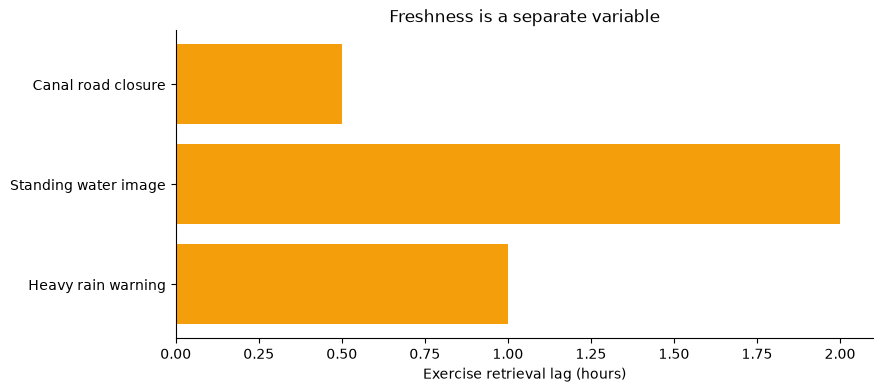

In [3]:
fig,ax=plt.subplots();ax.barh([e['event'] for e in exercise_events],[e['lag_h'] for e in exercise_events],color='#f59e0b');ax.set(xlabel='Exercise retrieval lag (hours)',title='Freshness is a separate variable');plt.show()

## Field exercise and review
Choose one provider and write down event time, retrieval time, coordinates, and license or use terms. For the exercise, decide which item warrants an immediate verification call.

## Source desk
- [OSIRIS source and MIT license](https://github.com/simplifaisoul/osiris) Â· [OSIRIS live console](https://osirisai.live/)
- [USGS Earthquake API](https://earthquake.usgs.gov/fdsnws/event/1/) Â· [NASA EONET](https://eonet.gsfc.nasa.gov/docs/v3) Â· [NASA FIRMS](https://firms.modaps.eosdis.nasa.gov/)
- [NOAA National Hurricane Center](https://www.nhc.noaa.gov/) Â· [GDACS](https://www.gdacs.org/) Â· [OpenSky Network](https://opensky-network.org/)

**Use rule:** A source link provides context, not independent confirmation of this fictional exercise. Check timestamps, geography, provider terms, and incident command procedures before any real decision.